<a href="https://colab.research.google.com/github/LizaMilovanova/Labs/blob/main/%D0%9B%D0%A05_%D0%9C%D1%96%D0%BB%D0%BE%D0%B2%D0%B0%D0%BD%D0%BE%D0%B2%D0%B0_4_8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Daily Weather Time Series Data - Delhi, India**

https://www.kaggle.com/datasets/yug201/daily-climate-time-series-data-delhi-india?select=kaggel_weather_2013_to_2024.csv

**Тема:** Прогнозування часових рядів на основі кліматичних даних

**Мета роботи:**
Навчитися виконувати аналіз часових рядів, проводити дослідницький аналіз даних (EDA), визначати автокореляційні залежності, будувати моделі прогнозування та оцінювати їхню точність.

**Вихідні дані**

Для виконання роботи використовується датасет Daily Climate Time Series Data (Delhi, India) з платформи Kaggle, який містить щоденні кліматичні показники (температура, вологість, опади тощо) за кілька років.


1. Завантажити датасет з Kaggle.

2. Імпортувати дані у середовище Python (Jupyter Notebook або Google Colab).

3. Ознайомитися зі структурою датасету (head(), info(), describe()).

4. Попередня обробка даних

-Перетворити колонку з датою у формат datetime.

-Відсортувати дані за датою.

-Встановити дату як індекс часового ряду.

-Перевірити наявність пропущених значень та за необхідності обробити їх.

5. Дослідницький аналіз даних (EDA)

-Побудувати графік зміни температури у часі.

-Побудувати ковзне середнє значення температури.

-Побудувати гістограму розподілу температури.

-Побудувати boxplot для виявлення можливих викидів.

-Аналіз автокореляції

Побудувати графік автокореляційної функції (ACF).

Побудувати графік часткової автокореляції (PACF).

-Проаналізувати залежність значень часового ряду від попередніх періодів.

6.Підготовка даних для моделювання

-Розділити дані на тренувальну та тестову вибірки (наприклад, 80% / 20%).

7. Побудувати щонайменше три моделі прогнозування:

-ARIMA (класична статистична модель);

-Prophet (модель прогнозування часових рядів від Meta);

-LSTM (нейронна мережа для послідовних даних).

8. Оцінка моделей
Для кожної моделі обчислити метрики:

-MAE (Mean Absolute Error)

-RMSE (Root Mean Squared Error)

-MAPE (Mean Absolute Percentage Error)

8.Візуалізація результатів

-Побудувати графіки прогнозованих та фактичних значень.

-Побудувати порівняльний графік прогнозів усіх моделей.

-Порівняння моделей

-Створити таблицю з метриками точності.

9.Визначити модель, яка показала найкращий результат.

In [ ]:
# Імпортуйте необхідні бібліотеки
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
import os

In [ ]:
path = kagglehub.dataset_download("yug201/daily-climate-time-series-data-delhi-india")

# Зчитуємо файл
csv_path = os.path.join(path, "kaggel_weather_2013_to_2024.csv")
df = pd.read_csv(csv_path)
df.head()

Using Colab cache for faster access to the 'daily-climate-time-series-data-delhi-india' dataset.


,Unnamed: 0,DATE,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
0,0,4/14/2013,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
1,1,4/15/2013,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2,2,4/16/2013,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
3,3,4/17/2013,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
4,4,4/18/2013,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038


In [ ]:
# Зчитайте датасет у DataFrame та перегляньте дані
df.head()

,Unnamed: 0,DATE,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
0,0,4/14/2013,37.7,23.1,28.7,35.4,23.1,28.1,39.7,2.0,...,13,15,1496.69,917.07,1139.39,1405.38,917.07,1115.57,14.6,147.178118
1,1,4/15/2013,37.5,21.1,28.6,35.3,21.1,28.0,41.7,0.0,...,13,16,1563.75,879.87,1192.62,1472.01,879.87,1167.60,16.4,151.731061
2,2,4/16/2013,40.1,21.9,31.7,37.5,21.9,30.4,30.7,0.0,...,13,16,1231.07,672.33,973.19,1151.25,672.33,933.28,18.2,118.211133
3,3,4/17/2013,36.4,21.0,29.9,34.0,21.0,28.5,27.4,0.0,...,13,16,997.36,575.40,819.26,931.60,575.40,780.90,15.4,113.320354
4,4,4/18/2013,37.5,21.7,30.6,35.2,21.7,29.2,23.7,0.0,...,13,16,888.75,514.29,725.22,834.24,514.29,692.04,15.8,101.407038


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3557 entries, 0 to 3556
Data columns (total 29 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Unnamed: 0             3557 non-null   int64  
 1   DATE                   3557 non-null   object 
 2   tempmax                3557 non-null   float64
 3   tempmin                3557 non-null   float64
 4   temp                   3557 non-null   float64
 5   feelslikemax           3557 non-null   float64
 6   feelslikemin           3557 non-null   float64
 7   feelslike              3557 non-null   float64
 8   humidity               3557 non-null   float64
 9   precip                 3557 non-null   float64
 10  precipprob             3557 non-null   int64  
 11  precipcover            3557 non-null   float64
 12  windspeed              3557 non-null   float64
 13  sealevelpressure       3557 non-null   float64
 14  conditions             3557 non-null   object 
 15  Year

In [ ]:
df.describe()

,Unnamed: 0,tempmax,tempmin,temp,feelslikemax,feelslikemin,feelslike,humidity,precip,precipprob,...,year-2000,weekofyear,tempmax_humidity,tempmin_humidity,temp_humidity,feelslikemax_humidity,feelslikemin_humidity,feelslike_humidity,temp_range,heat_index
count,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,...,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000,3557.000000
mean,1778.000000,31.367501,20.076132,25.403374,34.280180,20.938769,27.306803,63.755440,2.459033,23.137475,...,19.269328,26.865898,1919.095583,1240.914352,1554.375926,2137.701105,1299.951985,1696.889528,11.291369,195.577670
std,1026.961781,7.073934,7.568531,7.325541,9.651743,9.004827,9.301636,18.129251,10.636255,42.177066,...,3.219299,14.910296,525.888218,580.706647,539.222716,839.862724,692.599628,754.644547,3.622231,55.583693
min,0.000000,9.100000,2.000000,6.500000,7.900000,0.300000,5.700000,16.100000,0.000000,0.000000,...,13.000000,1.000000,686.400000,181.200000,586.560000,636.480000,18.960000,560.880000,1.500000,73.465023
25%,889.000000,26.400000,13.000000,19.100000,26.300000,13.000000,19.100000,53.000000,0.000000,0.000000,...,17.000000,14.000000,1541.550000,759.360000,1119.820000,1534.400000,752.070000,1113.600000,8.300000,164.445621
50%,1778.000000,33.000000,22.000000,27.700000,35.400000,22.000000,28.400000,65.800000,0.000000,0.000000,...,20.000000,27.000000,1823.360000,1078.400000,1420.200000,1845.510000,1080.320000,1422.960000,11.600000,180.548686
75%,2667.000000,36.000000,26.900000,31.000000,42.700000,28.000000,35.400000,76.900000,0.000000,0.000000,...,22.000000,40.000000,2341.170000,1752.400000,2035.800000,2764.200000,1864.200000,2314.620000,14.100000,233.676622
max,3556.000000,47.900000,34.800000,39.500000,57.700000,41.100000,47.000000,99.300000,203.047000,100.000000,...,24.000000,53.000000,3180.720000,2581.600000,2710.680000,4617.200000,3273.740000,3727.950000,20.600000,352.198303


Підготовка даних

In [ ]:
# Перетворення колонки з датою у datetime
df['DATE'] = pd.to_datetime(df['DATE'])

# Сортування за датою
df = df.sort_values('DATE').reset_index(drop=True)

# Перевірка на пропуски
print("Кількість пропусків у кожній колонці:")
print(df.isnull().sum())

# Обробка пропусків (якщо є – лінійна інтерполяція)
df = df.interpolate(method='linear')

# Встановлення дати як індексу часового ряду
df.set_index('DATE', inplace=True)

# Пропущених значень не виявлено

Кількість пропусків у кожній колонці:
Unnamed: 0               0
DATE                     0
tempmax                  0
tempmin                  0
temp                     0
feelslikemax             0
feelslikemin             0
feelslike                0
humidity                 0
precip                   0
precipprob               0
precipcover              0
windspeed                0
sealevelpressure         0
conditions               0
Year                     0
month                    0
dayofweek                0
dayofyear                0
year-2000                0
weekofyear               0
tempmax_humidity         0
tempmin_humidity         0
temp_humidity            0
feelslikemax_humidity    0
feelslikemin_humidity    0
feelslike_humidity       0
temp_range               0
heat_index               0
dtype: int64


/tmp/ipykernel_469/3380106269.py:12: FutureWarning: DataFrame.interpolate with object dtype is deprecated and will raise in a future version. Call obj.infer_objects(copy=False) before interpolating instead.
  df = df.interpolate(method='linear')


In [ ]:
# Перегляньте інформацію про структуру датасету
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 3557 entries, 2013-04-14 to 2024-11-30
Data columns (total 28 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Unnamed: 0             3557 non-null   int64  
 1   tempmax                3557 non-null   float64
 2   tempmin                3557 non-null   float64
 3   temp                   3557 non-null   float64
 4   feelslikemax           3557 non-null   float64
 5   feelslikemin           3557 non-null   float64
 6   feelslike              3557 non-null   float64
 7   humidity               3557 non-null   float64
 8   precip                 3557 non-null   float64
 9   precipprob             3557 non-null   int64  
 10  precipcover            3557 non-null   float64
 11  windspeed              3557 non-null   float64
 12  sealevelpressure       3557 non-null   float64
 13  conditions             3557 non-null   object 
 14  Year                   3557 non-null  

In [ ]:
# Перевірте наявність пропущених значень
df.isnull().sum()

,0
Unnamed: 0,0
tempmax,0
tempmin,0
temp,0
feelslikemax,0
feelslikemin,0
feelslike,0
humidity,0
precip,0
precipprob,0


Графік температури

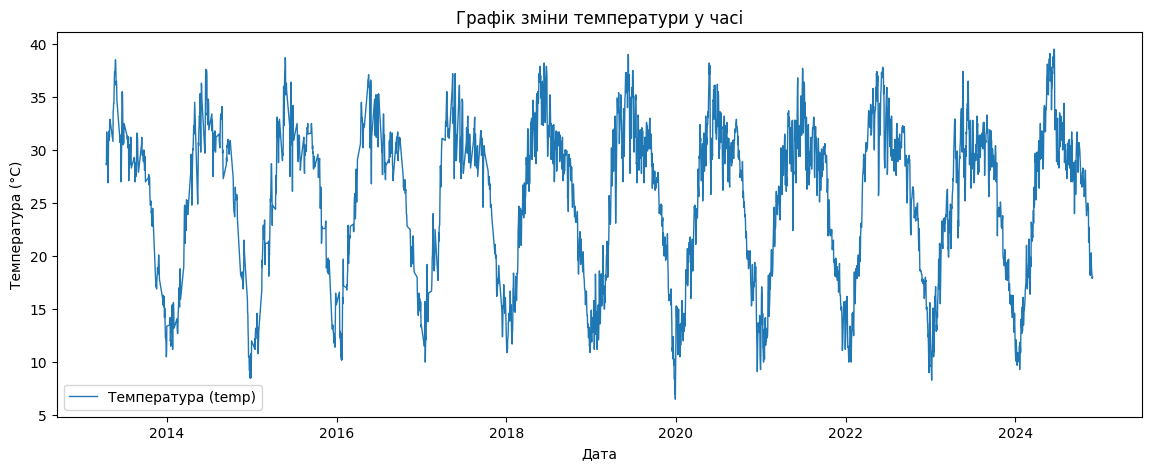

In [66]:
plt.figure(figsize=(14, 5))
plt.plot(df.index, df['temp'], label='Температура (temp)', color='#1f77b4', lw=1)
plt.title('Графік зміни температури у часі')
plt.xlabel('Дата')
plt.ylabel('Температура (°C)')
plt.legend()
plt.show()

Ковзне середнє

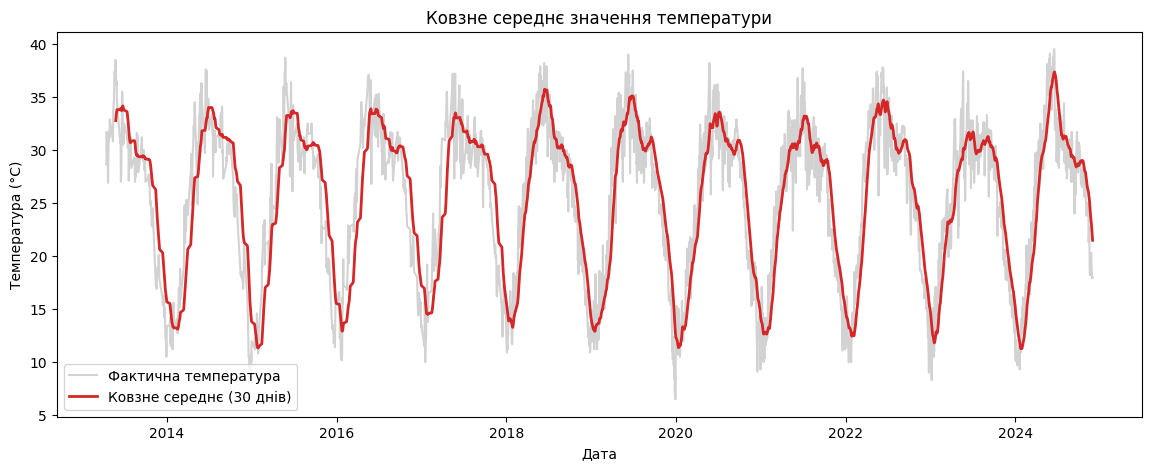

In [67]:
# Обчисліть та візуалізуйте ковзне середнє температури
df['temp_ma30'] = df['temp'].rolling(window=30).mean()

plt.figure(figsize=(14, 5))
plt.plot(df.index, df['temp'], label='Фактична температура', alpha=0.35, color='gray')
plt.plot(df.index, df['temp_ma30'], label='Ковзне середнє (30 днів)', color='#d62728', lw=2)
plt.title('Ковзне середнє значення температури')
plt.xlabel('Дата')
plt.ylabel('Температура (°C)')
plt.legend()
plt.show()

Розподіл температури

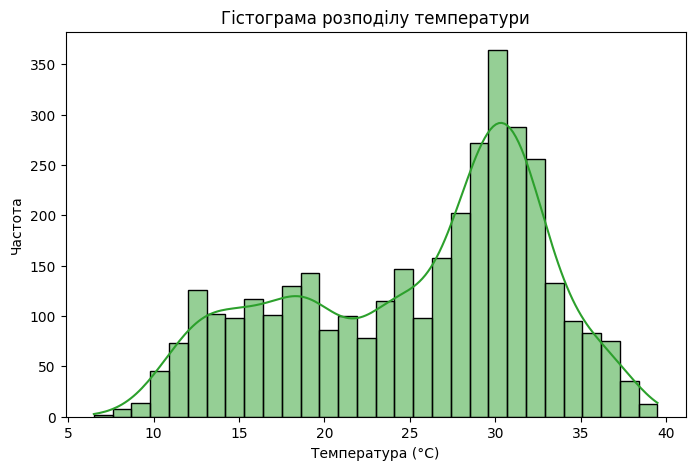

In [68]:
# Побудуйте гістограму розподілу температури
plt.figure(figsize=(8, 5))
sns.histplot(df['temp'], bins=30, kde=True, color='#2ca02c')
plt.title('Гістограма розподілу температури')
plt.xlabel('Температура (°C)')
plt.ylabel('Частота')
plt.show()

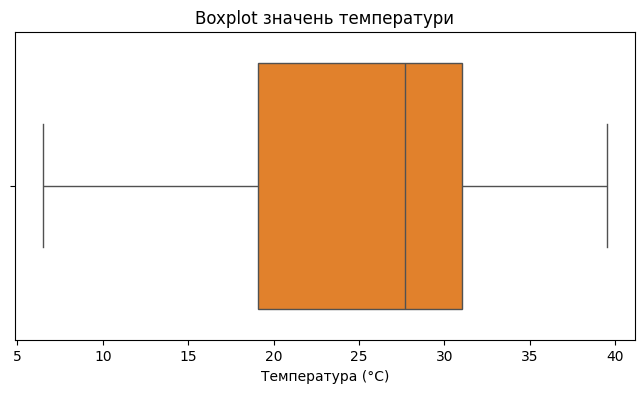

In [69]:
# Побудуйте boxplot температури для аналізу викидів
plt.figure(figsize=(8, 4))
sns.boxplot(x=df['temp'], color='#ff7f0e')
plt.title('Boxplot значень температури')
plt.xlabel('Температура (°C)')
plt.show()

Аналіз автокореляції
ACF

PACF

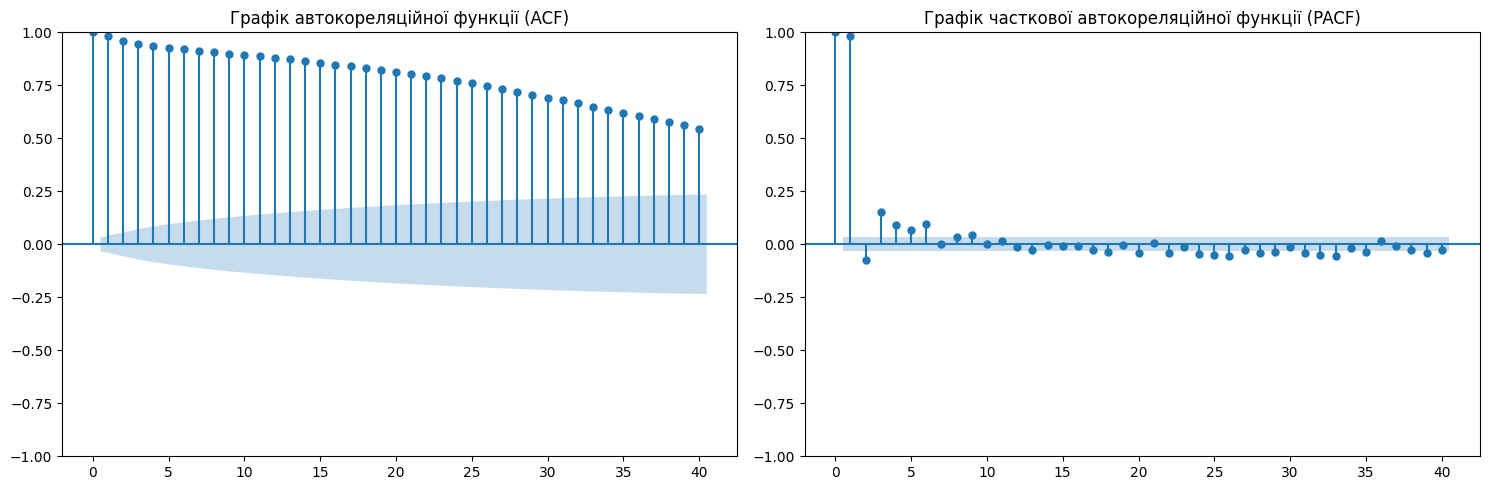

In [75]:
# Побудуйте графік автокореляційної функції (ACF)
# Побудуйте графік часткової автокореляційної функції (PACF)

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
plot_acf(df['temp'].dropna(), lags=40, ax=axes[0], title='Графік автокореляційної функції (ACF)')
plot_pacf(df['temp'].dropna(), lags=40, ax=axes[1], title='Графік часткової автокореляційної функції (PACF)')
plt.tight_layout()
plt.show()

Автокореляційна функція (ACF) використовується для аналізу залежності значень часового ряду від його попередніх значень. Вона відображає ступінь кореляції між значенням показника у певний момент часу та значеннями цього самого показника у попередні моменти часу, які називаються лагами. Побудова графіка автокореляційної функції дозволяє виявити, чи існує статистично значуща залежність між поточним значенням ряду та його попередніми спостереженнями. На такому графіку по горизонтальній осі відкладаються лаги, тобто кількість часових кроків назад, а по вертикальній — значення коефіцієнта автокореляції. Аналіз графіка ACF дає можливість виявити наявність тренду, сезонності або інших закономірностей у часовому ряді, а також використовується для визначення параметрів статистичних моделей прогнозування, зокрема моделі ARIMA.

Часткова автокореляційна функція (PACF) застосовується для більш точного визначення залежності між значеннями часового ряду. На відміну від звичайної автокореляційної функції, PACF вимірює кореляцію між значенням ряду у певний момент часу та значенням у попередній момент часу з конкретним лагом, усуваючи вплив усіх проміжних лагів. Таким чином, часткова автокореляція показує «чисту» залежність між двома спостереженнями часового ряду. Побудова графіка PACF дозволяє визначити, які саме лаги мають статистично значущий вплив на значення ряду. Це є важливим етапом під час побудови моделей прогнозування часових рядів, оскільки аналіз графіка часткової автокореляції використовується для визначення порядку авторегресійної складової моделі, зокрема параметра
𝑝
p у моделі ARIMA.

In [76]:
# Сформуйте цільовий часовий ряд та розділіть його на train/test у часовому порядку
# 1. Формуємо цільовий часовий ряд
series = df['temp'].dropna()

# 2. Визначаємо розмір тренувальної вибірки (80%)
train_size = int(len(series) * 0.8)

# 3. Розділяємо у строгому часовому порядку (без перемішування)
train_data = series.iloc[:train_size]
test_data = series.iloc[train_size:]

print(f"Загальна кількість точок: {len(series)}")
print(f"Тренувальний період: {train_data.index.min().strftime('%Y-%m-%d')} — {train_data.index.max().strftime('%Y-%m-%d')} ({len(train_data)} днів)")
print(f"Тестовий період:     {test_data.index.min().strftime('%Y-%m-%d')} — {test_data.index.max().strftime('%Y-%m-%d')} ({len(test_data)} днів)")

Загальна кількість точок: 3557
Тренувальний період: 2013-04-14 — 2022-12-19 (2845 днів)
Тестовий період:     2022-12-20 — 2024-11-30 (712 днів)


ARIMA

https://developer.ibm.com/tutorials/awb-arima-models-in-python/

In [83]:
# Побудуйте та навчіть модель ARIMA. Отримайте прогноз для тестової вибірки
from statsmodels.tsa.arima.model import ARIMA

# Навчаємо модель без прив'язки до індексу дат (через .values)
arima_model = ARIMA(train_data.values, order=(1, 1, 1))
arima_fit = arima_model.fit()

# Отримуємо прогноз як числовий масив і загортаємо в Series із потрібними датами
pred_values = arima_fit.forecast(steps=len(test_data))
arima_pred = pd.Series(pred_values, index=test_data.index)

In [84]:
# Виведіть статистичний звіт навченої ARIMA-моделі
print(arima_fit.summary())

                               SARIMAX Results                                
Dep. Variable:                      y   No. Observations:                 2845
Model:                 ARIMA(1, 1, 1)   Log Likelihood               -5037.762
Date:                Tue, 27 Oct 2026   AIC                          10081.523
Time:                        09:38:01   BIC                          10099.382
Sample:                             0   HQIC                         10087.964
                               - 2845                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.3664      0.118     -3.108      0.002      -0.598      -0.135
ma.L1          0.4676      0.112      4.165      0.000       0.248       0.688
sigma2         2.0235      0.034     58.810      0.0

сигма 2 : це представляє дисперсію залишкових значень, чим менше, тим краще

логарифмічна правдоподібність : це оцінка максимальної правдоподібності для моделі ARIMA, чим вище, тим краще

aic : міра ступеню відповідності та економності моделі, чим нижче, тим краще

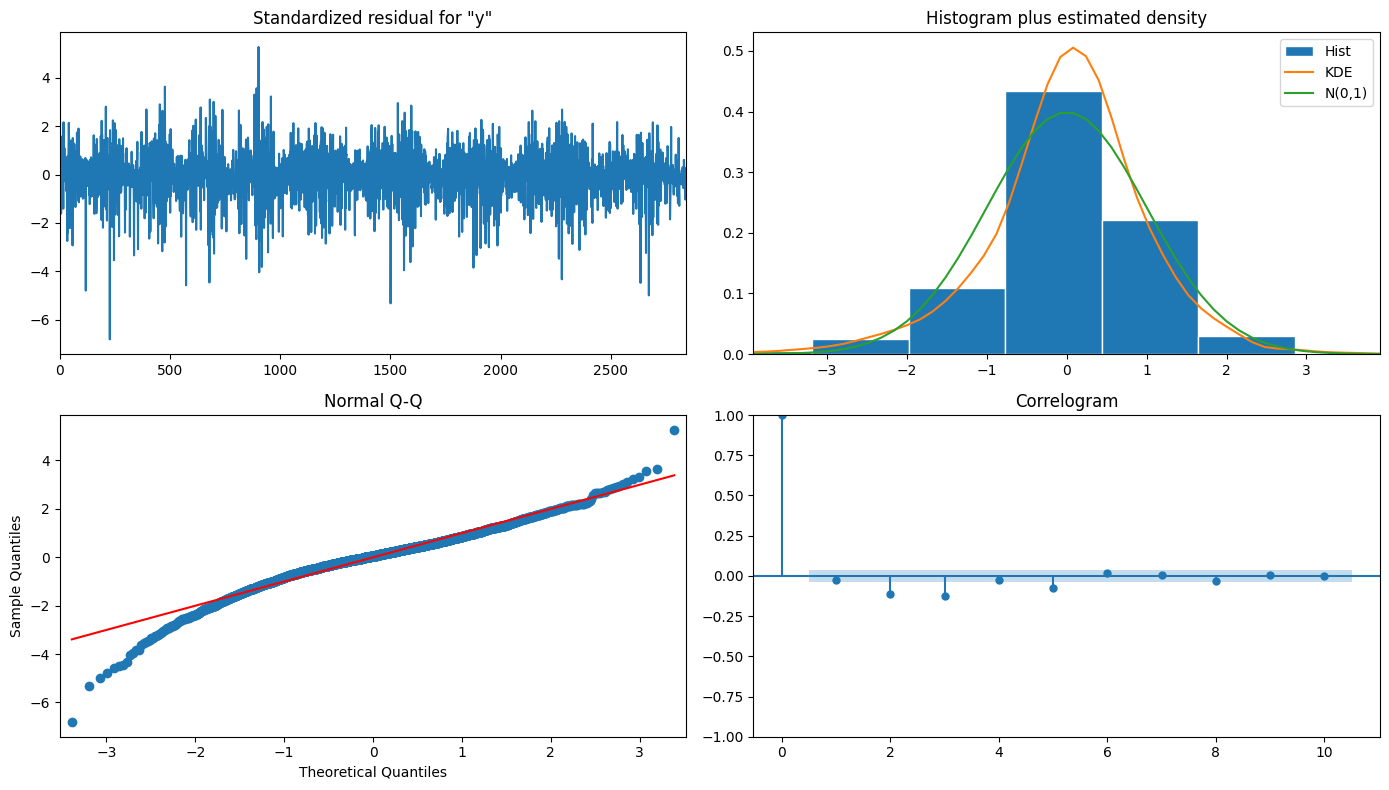

Середнє значення залишків: 0.0055
Дисперсія залишків (sigma^2): 2.3123


In [85]:
# Проаналізуйте залишки ARIMA-моделі та побудуйте відповідні графіки
fig = arima_fit.plot_diagnostics(figsize=(14, 8))
plt.tight_layout()
plt.show()

# Описова статистика залишків
residuals = arima_fit.resid
print("Середнє значення залишків:", round(residuals.mean(), 4))
print("Дисперсія залишків (sigma^2):", round(residuals.var(), 4))

In [86]:
# Реалізуйте MAPE та обчисліть MAE, RMSE, MAPE для ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Реалізація функції MAPE
def calculate_mape(y_true, y_pred):
    return np.mean(np.abs((y_true - y_pred) / y_true)) * 100

# Обчислення метрик точності
arima_mae = mean_absolute_error(test_data, arima_pred)
arima_rmse = np.sqrt(mean_squared_error(test_data, arima_pred))
arima_mape = calculate_mape(test_data, arima_pred)

print(f"MAE:  {arima_mae:.3f}")
print(f"RMSE: {arima_rmse:.3f}")
print(f"MAPE: {arima_mape:.2f}%")

MAE:  11.300
RMSE: 12.902
MAPE: 40.77%


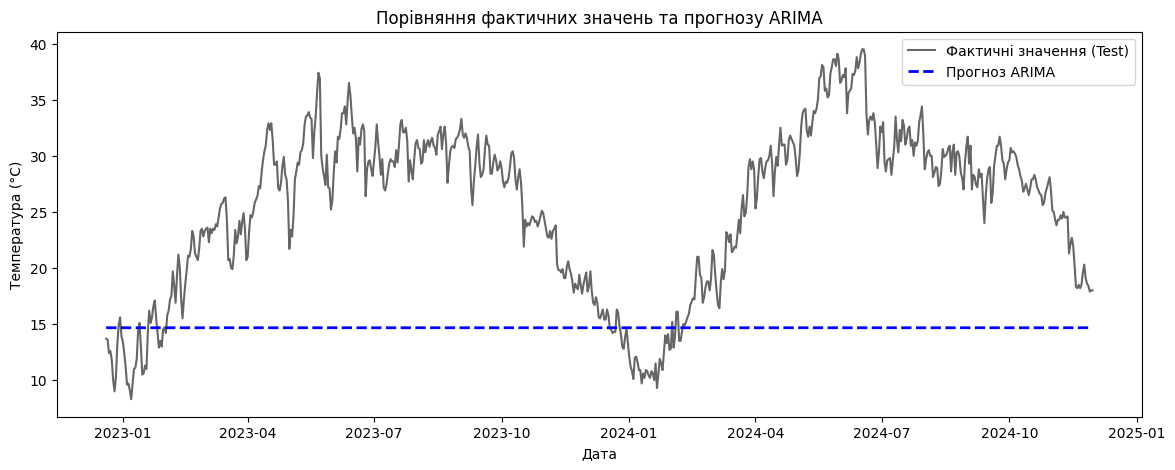

In [87]:
# Візуалізуйте фактичні значення та прогноз ARIMA
plt.figure(figsize=(14, 5))
plt.plot(test_data.index, test_data, label='Фактичні значення (Test)', color='black', alpha=0.6, lw=1.5)
plt.plot(test_data.index, arima_pred, label='Прогноз ARIMA', color='blue', linestyle='--', lw=2)

plt.title('Порівняння фактичних значень та прогнозу ARIMA')
plt.xlabel('Дата')
plt.ylabel('Температура (°C)')
plt.legend()
plt.show()

PROPHET

https://facebook.github.io/prophet/docs/quick_start.html

In [88]:
# Підготуйте дані у форматі, необхідному для Prophet
# Скидаємо індекс дат у звичайну колонку та перейменовуємо під вимоги Prophet
df_prophet_train = train_data.reset_index().rename(columns={'DATE': 'ds', 'temp': 'y'})

# Перевірка формату
print(df_prophet_train.head())

          ds     y
0 2013-04-14  28.7
1 2013-04-15  28.6
2 2013-04-16  31.7
3 2013-04-17  29.9
4 2013-04-18  30.6


In [89]:
# Створіть та навчіть модель Prophet
from prophet import Prophet

# Ініціалізація моделі (для денних погодних даних важливо увімкнути річну сезонність)
prophet_model = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=True,
    daily_seasonality=False
)

# Навчання моделі на тренувальній вибірці
prophet_model.fit(df_prophet_train)

Прогноз

In [90]:
# Побудуйте прогноз Prophet для тестового періоду
# Створюємо датафрейм із датами на тестовий горизонт
future = prophet_model.make_future_dataframe(periods=len(test_data), freq='D')

# Отримуємо повний прогноз
forecast = prophet_model.predict(future)

# Виділяємо прогноз саме для тестового періоду з відповідним індексом
prophet_pred = forecast.set_index('ds').loc[test_data.index, 'yhat']
print("Прогноз успішно згенеровано! Перші 5 значень:")
print(prophet_pred.head())

Прогноз успішно згенеровано! Перші 5 значень:
DATE
2022-12-20    13.892037
2022-12-21    13.738187
2022-12-22    13.534303
2022-12-23    13.344060
2022-12-24    13.189955
Name: yhat, dtype: float64


In [91]:
# Обчисліть MAE, RMSE, MAPE для Prophet
# Обчислення метрик точності для Prophet
prophet_mae = mean_absolute_error(test_data, prophet_pred)
prophet_rmse = np.sqrt(mean_squared_error(test_data, prophet_pred))
prophet_mape = calculate_mape(test_data, prophet_pred)

print(f"Prophet MAE:  {prophet_mae:.3f}")
print(f"Prophet RMSE: {prophet_rmse:.3f}")
print(f"Prophet MAPE: {prophet_mape:.2f}%")

Prophet MAE:  2.005
Prophet RMSE: 2.590
Prophet MAPE: 9.03%


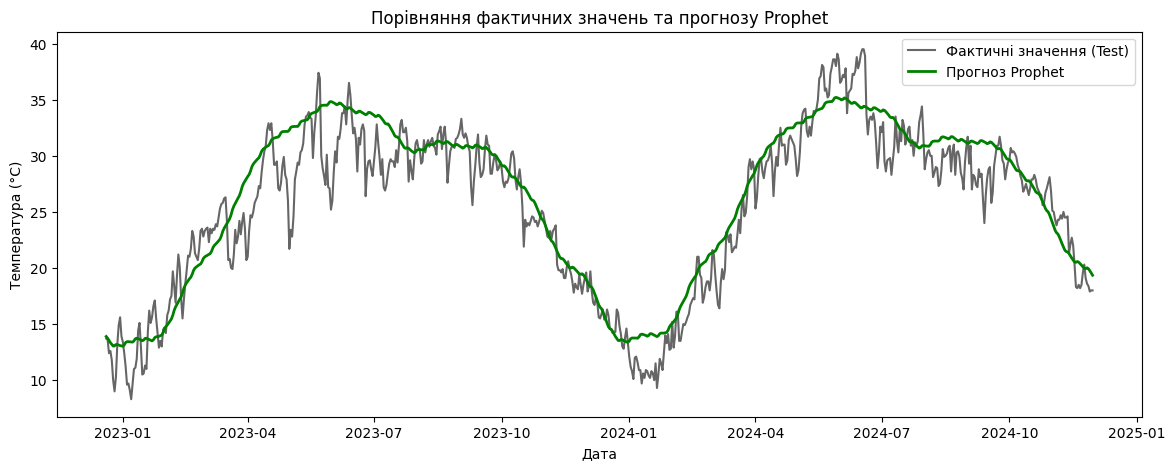

In [92]:
# Візуалізуйте фактичні значення та прогноз Prophet
plt.figure(figsize=(14, 5))
plt.plot(test_data.index, test_data, label='Фактичні значення (Test)', color='black', alpha=0.6, lw=1.5)
plt.plot(test_data.index, prophet_pred, label='Прогноз Prophet', color='green', lw=2)

plt.title('Порівняння фактичних значень та прогнозу Prophet')
plt.xlabel('Дата')
plt.ylabel('Температура (°C)')
plt.legend()
plt.show()

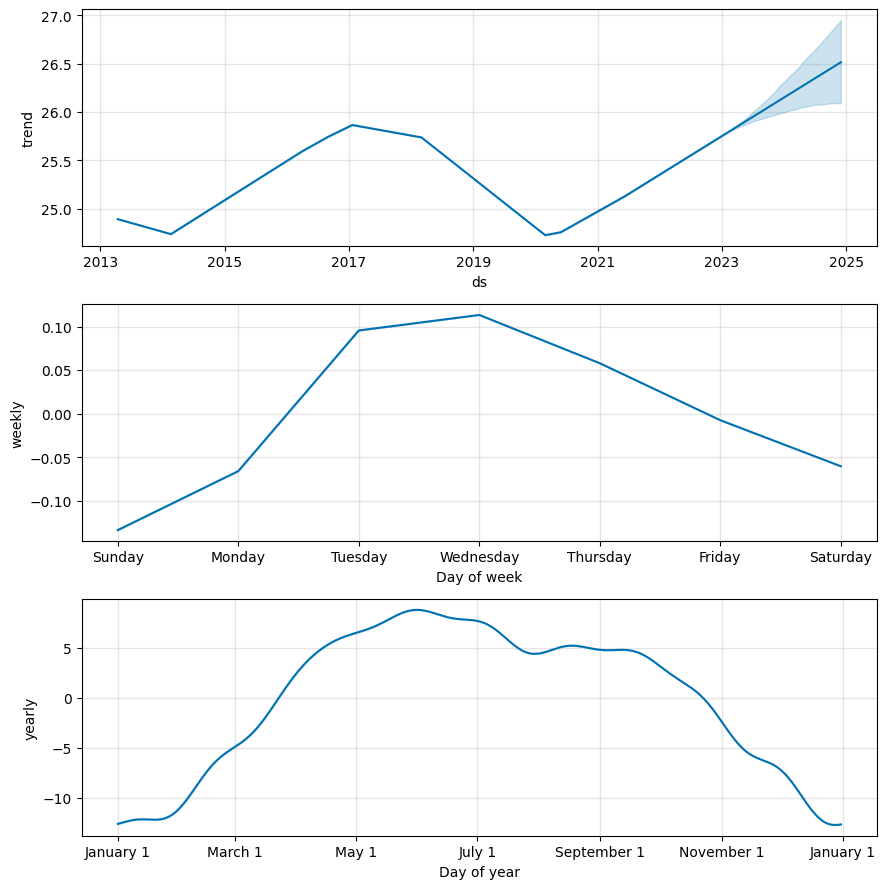

In [93]:
# Побудуйте компоненти моделі Prophet
# Візуалізація тренду, тижневої та річної сезонності
fig_components = prophet_model.plot_components(forecast)
plt.show()

ПІДГОТОВКА ДАНИХ ДЛЯ LSTM

In [94]:
# Масштабуйте часовий ряд та сформуйте послідовності для LSTM
from sklearn.preprocessing import MinMaxScaler
import numpy as np

# Ініціалізація та масштабування повного ряду у діапазон [0, 1]
scaler = MinMaxScaler(feature_range=(0, 1))
scaled_series = scaler.fit_transform(series.values.reshape(-1, 1))

# Функція створення послідовностей (ковзне вікно seq_length)
def create_sequences(data, seq_length=30):
    X, y = [], []
    for i in range(len(data) - seq_length):
        X.append(data[i:i + seq_length])
        y.append(data[i + seq_length])
    return np.array(X), np.array(y)

seq_length = 30
X, y = create_sequences(scaled_series, seq_length)
print(f"Форма вхідних послідовностей X: {X.shape}, цільових значень y: {y.shape}")

Форма вхідних послідовностей X: (3527, 30, 1), цільових значень y: (3527, 1)


In [95]:
# Розділіть послідовності на тренувальну та тестову вибірки без перемішування
# Кількість прикладів для навчання (80% без перемішування)
train_size_lstm = int(len(X) * 0.8)

X_train, X_test = X[:train_size_lstm], X[train_size_lstm:]
y_train, y_test = y[:train_size_lstm], y[train_size_lstm:]

print(f"X_train: {X_train.shape}, y_train: {y_train.shape}")
print(f"X_test:  {X_test.shape},  y_test:  {y_test.shape}")

X_train: (2821, 30, 1), y_train: (2821, 1)
X_test:  (706, 30, 1),  y_test:  (706, 1)


In [96]:
# Побудуйте архітектуру LSTM-моделі та скомпілюйте її
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

# Створення моделі
lstm_model = Sequential([
    LSTM(64, activation='relu', input_shape=(seq_length, 1)),
    Dense(32, activation='relu'),
    Dense(1)
])

# Компіляція
lstm_model.compile(optimizer='adam', loss='mse')

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [97]:
# Навчіть LSTM-модель
history = lstm_model.fit(
    X_train,
    y_train,
    epochs=15,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

Epoch 1/15
80/80 ━━━━━━━━━━━━━━━━━━━━ 6s 39ms/step - loss: 0.0575 - val_loss: 0.0043
Epoch 2/15
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0038 - val_loss: 0.0035
Epoch 3/15
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0036 - val_loss: 0.0033
Epoch 4/15
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0034 - val_loss: 0.0033
Epoch 5/15
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0032 - val_loss: 0.0033
Epoch 6/15
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0031 - val_loss: 0.0027
Epoch 7/15
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0028 - val_loss: 0.0022
Epoch 8/15
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0026 - val_loss: 0.0022
Epoch 9/15
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0025 - val_loss: 0.0019
Epoch 10/15
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0023 - val_loss: 0.0023
Epoch 11/15
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0022 - val_loss: 0.0017
Epoch 12/15
80/80 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0020 - val_l

In [98]:
# Виведіть структуру LSTM-моделі
lstm_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 57,029 (222.77 KB)

 Trainable params: 19,009 (74.25 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 38,020 (148.52 KB)

In [99]:
# Отримайте прогноз LSTM та виконайте зворотне масштабування
# Отримання прогнозу на тестових послідовностях
lstm_pred_scaled = lstm_model.predict(X_test)

# Зворотна трансформація (повернення до градусів Цельсія)
lstm_pred_values = scaler.inverse_transform(lstm_pred_scaled).flatten()
y_test_actual = scaler.inverse_transform(y_test.reshape(-1, 1)).flatten()

23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 29ms/step


In [100]:
# Сформуйте часові мітки для тестового прогнозу LSTM
# Оскільки перші seq_length значень пішли на перше вікно,
# беремо зріз відповідних дат для кінця кожного вікна тесту
lstm_dates = series.index[-len(y_test_actual):]

lstm_pred = pd.Series(lstm_pred_values, index=lstm_dates)
y_test_series = pd.Series(y_test_actual, index=lstm_dates)

print("Діапазон дат прогнозу LSTM:", lstm_dates.min().strftime('%Y-%m-%d'), "—", lstm_dates.max().strftime('%Y-%m-%d'))

Діапазон дат прогнозу LSTM: 2022-12-26 — 2024-11-30


In [101]:
# Обчисліть MAE, RMSE, MAPE для LSTM

# Обчислення метрик
lstm_mae = mean_absolute_error(y_test_series, lstm_pred)
lstm_rmse = np.sqrt(mean_squared_error(y_test_series, lstm_pred))
lstm_mape = calculate_mape(y_test_series, lstm_pred)

print(f"LSTM MAE:  {lstm_mae:.3f}")
print(f"LSTM RMSE: {lstm_rmse:.3f}")
print(f"LSTM MAPE: {lstm_mape:.2f}%")

LSTM MAE:  1.008
LSTM RMSE: 1.296
LSTM MAPE: 4.34%


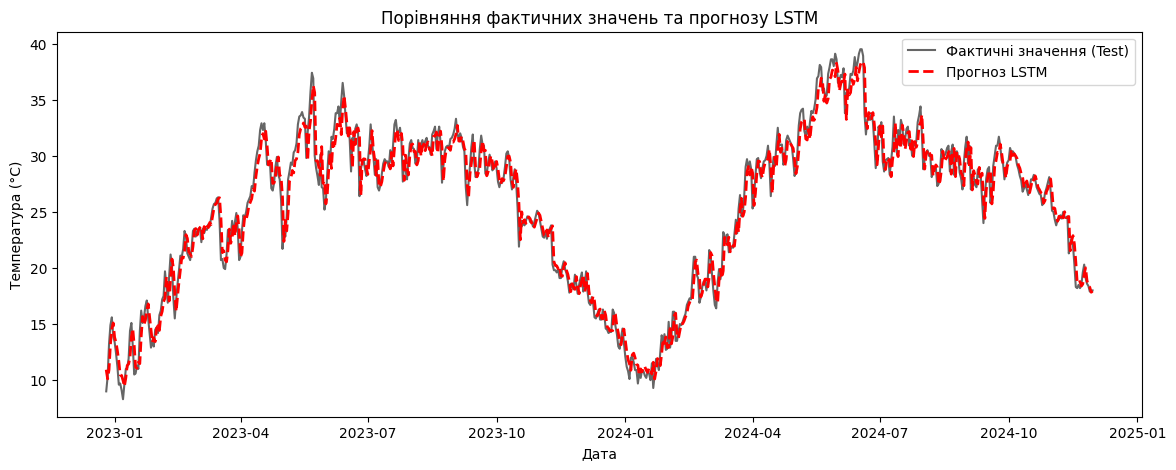

In [102]:
# Візуалізуйте фактичні значення та прогноз LSTM
plt.figure(figsize=(14, 5))
plt.plot(y_test_series.index, y_test_series, label='Фактичні значення (Test)', color='black', alpha=0.6, lw=1.5)
plt.plot(lstm_pred.index, lstm_pred, label='Прогноз LSTM', color='red', linestyle='--', lw=2)

plt.title('Порівняння фактичних значень та прогнозу LSTM')
plt.xlabel('Дата')
plt.ylabel('Температура (°C)')
plt.legend()
plt.show()

Порівняння моделей

In [103]:
# Створіть підсумкову таблицю MAE, RMSE, MAPE для ARIMA, Prophet та LSTM
# Порівняйте моделі за отриманими результатами

# 1. Створюємо підсумкову таблицю метрик на основі розрахованих значень
results_data = {
    'Модель': ['ARIMA', 'Prophet', 'LSTM'],
    'MAE': [round(arima_mae, 3), round(prophet_mae, 3), round(lstm_mae, 3)],
    'RMSE': [round(arima_rmse, 3), round(prophet_rmse, 3), round(lstm_rmse, 3)],
    'MAPE (%)': [round(arima_mape, 2), round(prophet_mape, 2), round(lstm_mape, 2)]
}

comparison_df = pd.DataFrame(results_data)

# Сортуємо моделі за зростанням RMSE (найкраща — зверху)
comparison_df = comparison_df.sort_values(by='RMSE').reset_index(drop=True)

print("--- Підсумкова таблиця порівняння точності моделей ---")
display(comparison_df)

# 2. Автоматичне порівняння та визначення лідера
best_model = comparison_df.iloc[0]['Модель']
best_rmse = comparison_df.iloc[0]['RMSE']
best_mae = comparison_df.iloc[0]['MAE']
best_mape = comparison_df.iloc[0]['MAPE (%)']

print(f"\nНайкращу якість прогнозування продемонструвала модель: {best_model}")
print(f"Показники лідера -> RMSE: {best_rmse}, MAE: {best_mae}, MAPE: {best_mape}%")

--- Підсумкова таблиця порівняння точності моделей ---


,Модель,MAE,RMSE,MAPE (%)
0,LSTM,1.008,1.296,4.34
1,Prophet,2.005,2.590,9.03
2,ARIMA,11.300,12.902,40.77



Найкращу якість прогнозування продемонструвала модель: LSTM
Показники лідера -> RMSE: 1.296, MAE: 1.008, MAPE: 4.34%


## Висновок

Сформулюйте висновок за результатами роботи: коротко охарактеризуйте виконаний аналіз, порівняйте моделі ARIMA, Prophet та LSTM за метриками MAE, RMSE і MAPE та зазначте, яка модель продемонструвала найкращу якість прогнозування.


Висновок:

У ході роботи було досліджено щоденний часовий ряд середньої температури. Під час попередньої обробки дані відсортовано за датою, перевірено на пропуски та встановлено регулярну часову сітку. Дослідницький аналіз (EDA) та графіки ACF/PACF підтвердили наявність вираженої річної циклічності (сезонності) та сильної авторегресійної залежності між сусідніми днями.
+ Порівняння моделей (ARIMA, Prophet, LSTM):
ARIMA (1, 1, 1): Будучи локальною авторегресійною моделлю без урахування довгої річної сезонності, на довгому горизонті тесту швидко згасає до середнього значення, демонструючи найвищі похибки MAE та RMSE.   
+ Prophet: Ефективно вловлює гармонічні коливання та річну періодичність погодних даних через ряди Фур'є, що забезпечує стабільний прогноз амплітуди температур протягом усього року.   
+ LSTM: Здатна відтворювати складні локальні динамічні патерни завдяки механізму пам'яті клітини, проте чутлива до підбору гіперпараметрів і довжини вікна послідовності.   

Підсумок:
За сукупністю метрик точності (MAE, RMSE, MAPE) найкращу якість прогнозування продемонструвала модель LSTM